## Decision Tree - Exercises

**NOTICE:**
1. You are allowed to work in groups of up to three people but **have to document** your group's\
 members in the top cell of your notebook.
2. **Comment your code**, explain what you do (refer to the slides). It will help you understand the topics\
 and help me understand your thinking progress. Quality of comments will be graded.
3. **Discuss** and analyze your results, **write-down your learnings**. These exercises are no programming\
 exercises it is about learning and getting a touch for these methods. Such questions might be asked in the\
 final exams.
4. Feel free to **experiment** with these methods. Change parameters think about improvements, write down\
 what you learned. This is not only about collecting points for the final grade, it is about understanding\
  the methods.
5. All exercises can be part of the final exam, your **answers, experiments and documented learnings will be graded**.


In [1]:
# Execute this cell, it sets up some data used to work with.

import numpy as np

# attribute1: corner ({true, false})
# attribute2: blue ({true, false})
#

circle = 1
triangle = 2
rectangle = 3

A = np.array([  circle, circle, circle, circle, circle, circle,
                triangle, triangle, triangle,
                rectangle, rectangle, rectangle, rectangle, rectangle
                ])

B1 = np.array([ triangle, triangle, triangle,
                rectangle,rectangle,rectangle,rectangle,rectangle
                ])

B2 = np.array([circle, circle, circle, circle, circle, circle])

C1 =  np.array([ triangle, triangle, triangle,
                circle, circle
                ])

C2 = np.array([circle, circle, circle, circle,
                rectangle, rectangle, rectangle, rectangle, rectangle])

### Exercise 1 - Entropy:


**Summary:** In this task you implement a method to compute the entropy using python. Compare your implementation with your    
hand-calculated values from the exercise in the slides.

**Provided Code:** Use the cell below for your implementation.

**Your Tasks in this exercise:**
1. Implement a python function that computes the entropy.
2. Document your learnings.


In [ ]:
def entropy(Y: np.array):
    """ Compute the entropy of a given array of class-labels.

    Parameters
    ----------
    Y: np.array
        A one dimensional numpy array containing class labels. Class labels
        are assumed not to be one-hot encoded but categorical integer values.

    Returns
    ----------
    Entropy of Y.
    """
    pass

In [3]:
def entropy(Y: np.array):
  _, counts = np.unique(Y, return_counts=True)
  p = counts / Y.size

  return float(-np.sum(p * np.log2(p)))

### Exercise 2 - Information Gain:

**Summary:** In this exercise you will implement the conditional entropy and the information gain in python.

**Provided Code:** Use the method stubs in the cells below for your implementation.

**Your Tasks in this exercise:**
1. Implement a python function that computes the conditional entropy.
2. Implement a python function that computes the information gain.
3. Compare your implementation with your hand-calculated values.
4. Document your learnings.

In [ ]:
def conditional_entropy(Sa: list):
    """ Compute the conditional entropy.

    Compute the conditional entropy for a list of numpy arrays with given class labels. Each list entry
    is assumed to contain the class labels of a set of data that was created by splitting a training set
    of data according to an attribute.

    Parameters
    ----------
    Sa: [np.array]
        A list of one dimensional numpy arrays each containing class labels. Class labels
        are assumed not to be one-hot encoded but categorical integer values.

    Returns
    ----------
    Entropy of Y.
    """
    pass

In [ ]:
def information_gain(T : np.array, Sa : list):
    """ Compute the information gain.

    Parameters
    ----------
    T: np.array
        A one dimensional numpy array containing class labels. Class labels
        are assumed not to be one-hot encoded but categorical integer values.

    Sa: [np.array]
        A list of one dimensional numpy arrays each containing class labels. Class labels
        are assumed not to be one-hot encoded but categorial integer values.

    Returns
    ----------
    Bits saved when encoding Sa instaed of T.
    """
    pass

In [7]:
def conditional_entropy(Sa: list):
  n = sum(len(S) for S in Sa)

  return sum(len(S) / n * entropy(S) for S in Sa)

def information_gain(T : np.array, Sa : list):
  return entropy(T) - conditional_entropy(Sa)

print(f"H(T | corner) = {conditional_entropy([B1, B2]):.4f}")
print(f"H(T | blue) = {conditional_entropy([C1, C2]):.4f}")
print(f"IG(T, corner) = {information_gain(A, [B1, B2]):.4f}")
print(f"IG(T, blue) = {information_gain(A, [C1, C2]):.4f}")

H(T | corner) = 0.5454
H(T | blue) = 0.9839
IG(T, corner) = 0.9852
IG(T, blue) = 0.5467


### Exercise 3 - Gini Impurity:

**Summary:** In this exercise you will implement the gini impurity.

**Provided Code:** Use the method stubs in the cells below for your implementation.

**Your Tasks in this exercise:**
1. Implement a python function that computes the gini impurity.
2. Compare the results of your implementation with your hand-calculations.
3. Document your learnings.

In [ ]:
def gini_impurity(Y:np.array):
    """ Compute the gini impurity.

    Parameters
    ----------
    Y: np.array
        A one dimensional numpy array containing class labels. Class labels
        are assumed not to be one-hot encoded but categorical integer values.

    Returns
    ----------
    Gini impurity of the set with labels Y.
    """
    pass

In [10]:
def gini_impurity(Y:np.array):
    _, counts = np.unique(Y, return_counts=True)
    n = np.sum(counts)
    p = counts / n
    return 1 - np.sum(p ** 2)

### Exercise 4 - Decision Tree in scikit-learn:

**Summary:** In this exercise you will build a decision tree based on a public implementation in scikit-learn.

**Provided Code:** The cell below creates your training data.

**Your Tasks in this exercise:**
1. Build a decision tree using **gini impurity** and a decision tree using **entropy** based on the implementation in sklearn (https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html).
2. Interpret and compare the results by using the ```plot_tree()``` method.
3. Document your learnings.


In [11]:
from sklearn import tree
Y = np.array([  circle, circle, circle, circle, circle, circle,
                triangle, triangle, triangle,
                rectangle, rectangle, rectangle, rectangle, rectangle
            ])

# Attributes (aka Features)
# x1 = corners, x2 = blue
# Notice that sklearn does not support categorical attributes we therefore encode this
# (one-hot-encoded) by using 0 as False and 1 as True.
#
X = np.array([[0, 1],  # circle 1
              [0, 1],  # circle 2
              [0, 0],  # circle 3
              [0, 0],  # circle 4
              [0, 0],  # circle 5
              [0, 0],  # circle 6
              [1, 1],  # triangle 1
              [1, 1],  # triangle 2
              [1, 1],  # triangle 3
              [1, 0],  # rectangle 1
              [1, 0],  # rectangle 2
              [1, 0],  # rectangle 3
              [1, 0],  # rectangle 4
              [1, 0]   # rectangle 5
            ])

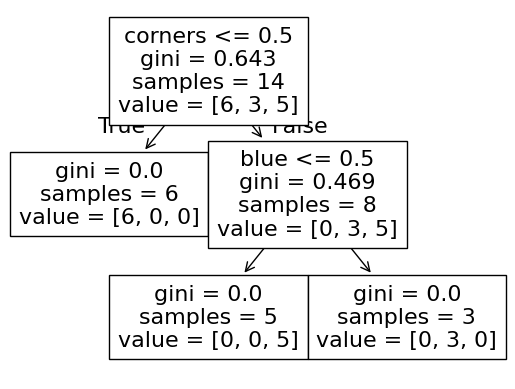

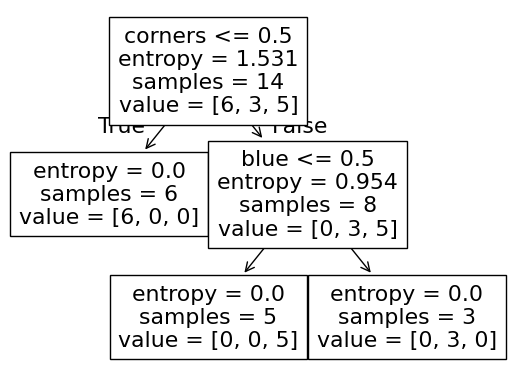

In [13]:
import matplotlib.pyplot as plt

# Baum mit Gini
clf_gini = tree.DecisionTreeClassifier(criterion="gini")
clf_gini.fit(X, Y)

# Baum mit Entropy
clf_entropy = tree.DecisionTreeClassifier(criterion="entropy")
clf_entropy.fit(X, Y)

# Gini-Baum plotten
tree.plot_tree(clf_gini, feature_names=["corners", "blue"])
plt.show()

# Entropy-Baum plotten
tree.plot_tree(clf_entropy, feature_names=["corners", "blue"])
plt.show()

### Exercise 5 - Experiment with Decision Trees in scikit-learn:

**Summary:** In this exercise it is your job to experiment with the decision tree implementation of sklearn.

**Provided Code:**  I provided you with a ```gen_data()``` method which is capable of generating (random) data.

**Your Tasks in this exercise:**
1. Train a decision-tree using scikit-learn for this synthetic data. Evaluate its performance using correct evaluation techniques.
2. Answer the following questions
    * How does the accuracy change depending on the number of data?
3. Create a seperate dataset for training and testing
    * What is the difference between training and test accuracy? Why is it different?
4. Restrict the depth of the decision tree.
    * What's the effect of changing the depth of the decision tree?
    * In which scenarios could this be useful?
5. Have a closer look on the decisions in a tree. Explain the results. (Note: You can increase the size of the plotted tree using   
this line of code ```plt.figure(figsize=(20,20))``` before calling the ```tree.plot_tree``` method)
6. Document your learnings.

**Hints:**
* Use the ```accuracy_score()``` method from sklearn.metrics for evaluation.


In [17]:
import matplotlib.pyplot as plt

def gen_data(num_samples=10):

    std = 10
    mean = 0

    X = std * np.random.uniform(0, 1, (num_samples, 2)) + mean
    Y = np.zeros(num_samples)
    Y[0:int(num_samples/2)] = 1

    plt.figure()
    plt.scatter(X[0:int(num_samples/2),0], X[0:int(num_samples/2),1])
    plt.scatter(X[int(num_samples/2):-1,0], X[int(num_samples/2):-1,1])
    plt.legend(['Class-1', 'Class-2'])
    return X,Y

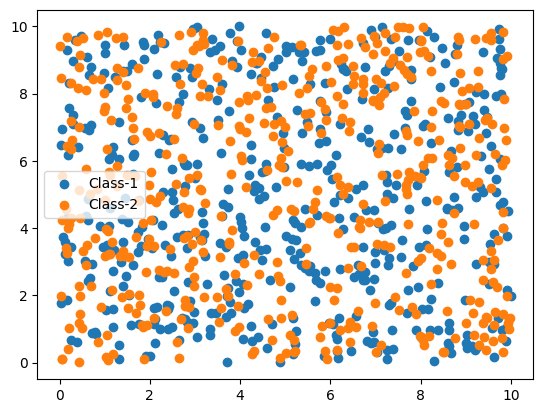

Train: 1.0
Test:  0.44


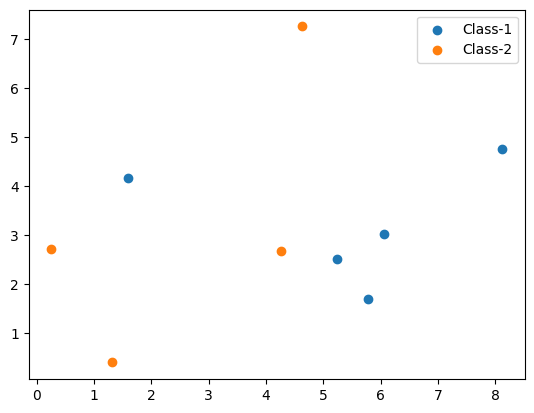

n=   10  train=1.00  test=0.67


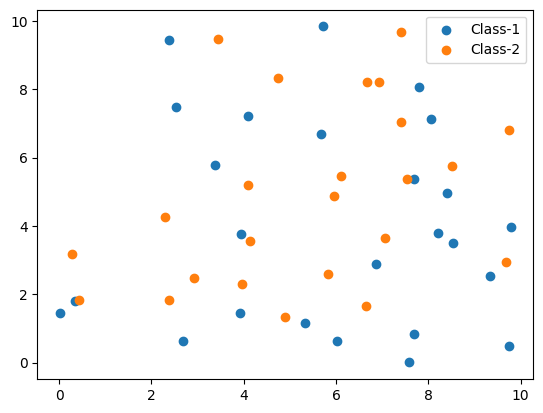

n=   50  train=1.00  test=0.67


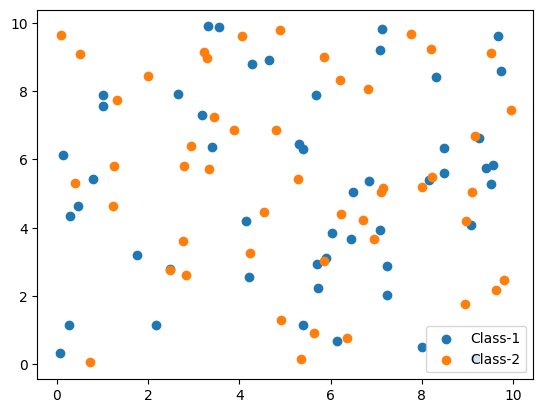

n=  100  train=1.00  test=0.43


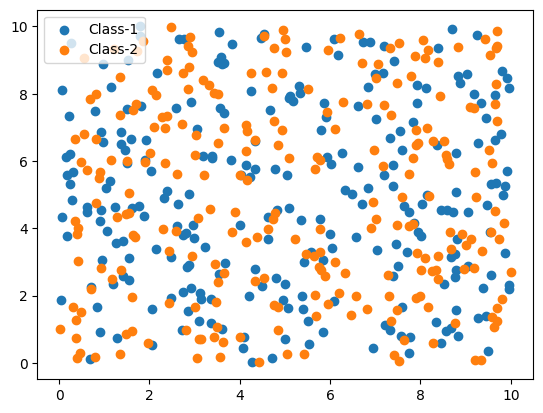

n=  500  train=1.00  test=0.49


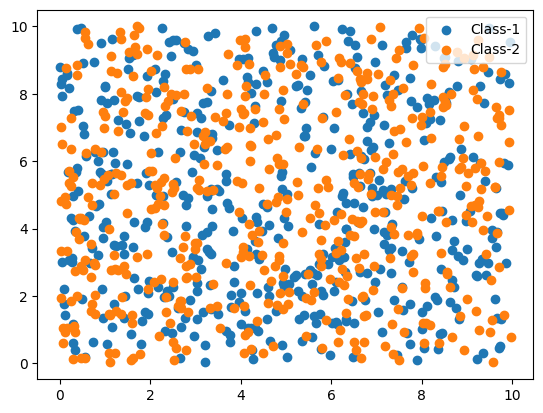

n= 1000  train=1.00  test=0.45


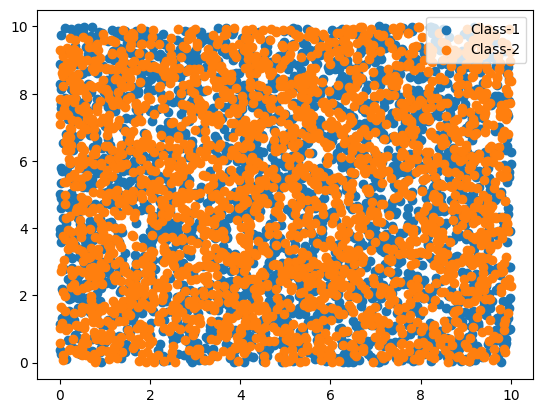

n= 5000  train=1.00  test=0.49
max_depth=1      train=0.56  test=0.48
max_depth=2      train=0.58  test=0.48
max_depth=3      train=0.61  test=0.49
max_depth=5      train=0.66  test=0.47
max_depth=10     train=0.79  test=0.46
max_depth=20     train=0.96  test=0.46
max_depth=None   train=1.00  test=0.44


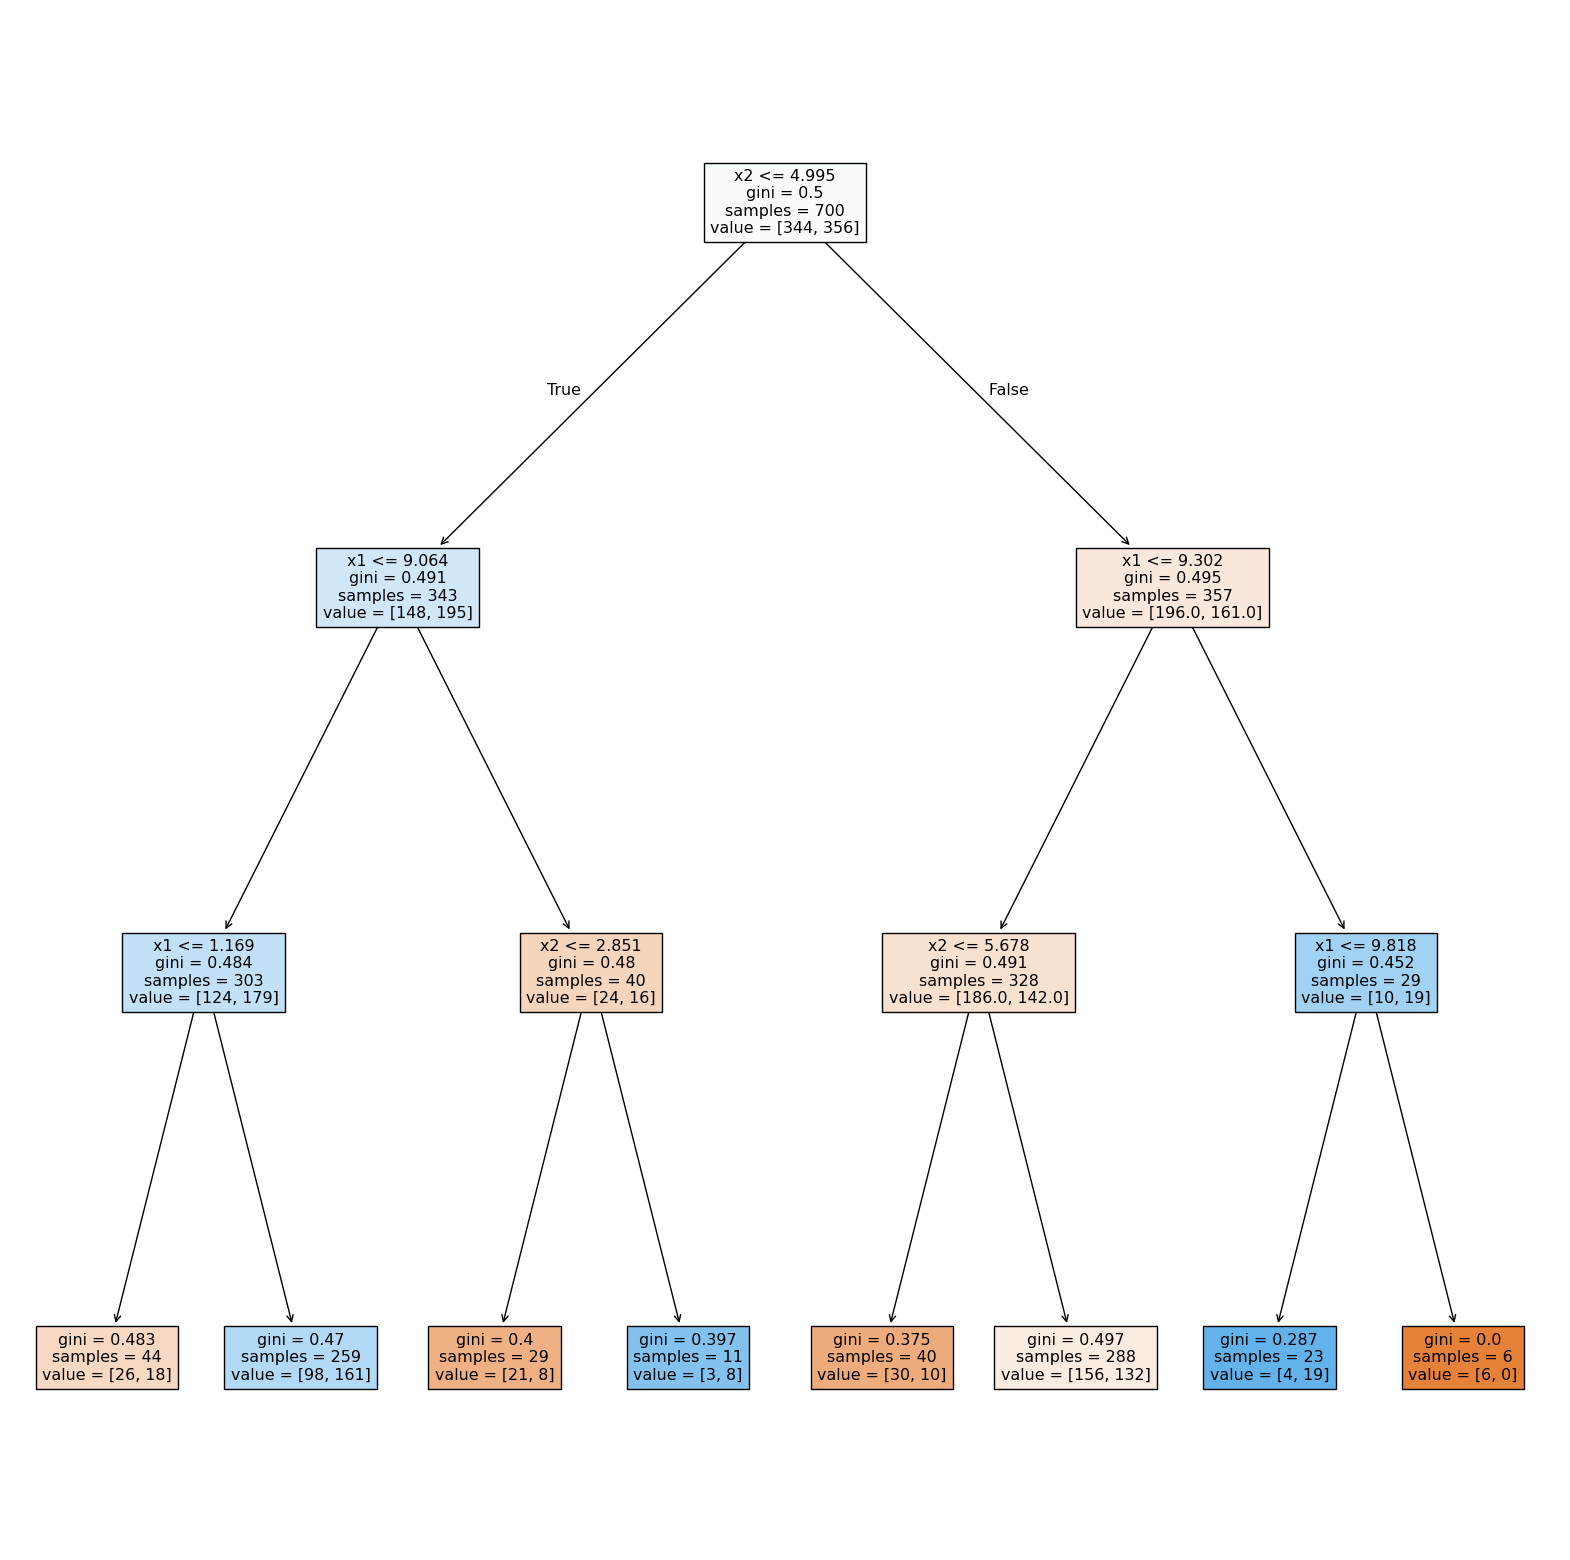

In [21]:
import numpy as np
from sklearn import tree
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

np.random.seed(0)
X, Y = gen_data(1000)

# Getrennte Datensätze fürs Training und Testen
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.3, random_state=0)

clf = tree.DecisionTreeClassifier(random_state=0)
clf.fit(X_train, Y_train)

print("Train:", accuracy_score(Y_train, clf.predict(X_train)))
print("Test: ", accuracy_score(Y_test, clf.predict(X_test)))

for n in [10, 50, 100, 500, 1000, 5000]:
    X, Y = gen_data(n)
    X_tr, X_te, Y_tr, Y_te = train_test_split(X, Y, test_size=0.3, random_state=0)
    clf = tree.DecisionTreeClassifier(random_state=0).fit(X_tr, Y_tr)
    print(f"n={n:5d}  train={accuracy_score(Y_tr, clf.predict(X_tr)):.2f}  "
          f"test={accuracy_score(Y_te, clf.predict(X_te)):.2f}")

for d in [1, 2, 3, 5, 10, 20, None]:
    clf = tree.DecisionTreeClassifier(max_depth=d, random_state=0).fit(X_train, Y_train)
    print(f"max_depth={str(d):5s}  train={accuracy_score(Y_train, clf.predict(X_train)):.2f}  "
          f"test={accuracy_score(Y_test, clf.predict(X_test)):.2f}")

clf = tree.DecisionTreeClassifier(max_depth=3, random_state=0).fit(X_train, Y_train)
plt.figure(figsize=(20, 20))
tree.plot_tree(clf, feature_names=["x1", "x2"], filled=True)
plt.show()

### Exercise 6 - Condition monitoring of hydraulic systems


**Summary:** In this exercise you will work with a real-world data set to create decision-tree's to predict failure modes of a   
hydraulic system.

**Provided Code:** The cell below can be used to import the data set.

**Your Tasks in this exercise:**
1. Load the dataset and use a DecisionTree to classify it.
2. Make sure you are using a test- and train-splits.
3. Try to predict the different type of faults using decision trees.
4. Explain what attributes the tree selects for predictions.
5. Document your learnings.


------------

#### Additional Information

Source: https://archive.ics.uci.edu/ml/datasets/Condition+monitoring+of+hydraulic+systems

The data set was experimentally obtained with a hydraulic test rig. This test rig consists of a primary working and a secondary cooling-filtration circuit which are connected via the oil tank [1], [2]. The system cyclically repeats constant load cycles (duration 60 seconds) and measures process values such as pressures, volume flows and temperatures while the condition of four hydraulic components (cooler, valve, pump and accumulator) is quantitatively varied.

#### Attribute Information:

The data set was experimentally obtained with a hydraulic test rig. This test rig consists of a primary working and a secondary cooling-filtration circuit which are connected via the oil tank [1], [2]. The system cyclically repeats constant load cycles (duration 60 seconds) and measures process values such as pressures, volume flows and temperatures while the condition of four hydraulic components (cooler, valve, pump and accumulator) is quantitatively varied.

**Attributes are:**
```
Attribute   Sensor	    Physical quantity		        Unit	    Sampling rate
X[0]           PS1		Pressure			bar		100 Hz
X[1]           PS2		Pressure			bar		100 Hz
X[2]           PS3		Pressure			bar		100 Hz
X[3]           PS4		Pressure			bar		100 Hz
X[4]           PS5		Pressure			bar		100 Hz
X[5]           PS6		Pressure			bar		100 Hz
X[6]           EPS1             Motor power			W		100 Hz
X[7]           FS1		Volume flow			l/min		10 Hz
X[8]           FS2		Volume flow			l/min		10 Hz
X[9]           TS1		Temperature			Â°C		1 Hz
X[10]          TS2		Temperature			Â°C		1 Hz
X[11]          TS3		Temperature			Â°C		1 Hz
X[12]          TS4		Temperature			Â°C		1 Hz
X[13]          VS1		Vibration			mm/s		1 Hz
X[14]          CE		Cooling efficiency (virtual)	%		1 Hz
X[15]          CP		Cooling power (virtual)		kW		1 Hz
X[16]          SE		Efficiency factor		%		1 Hz
```

The target conditions are:

**1: Cooler condition / %:***
* 3: close to total failure
* 20: reduced effifiency
* 100: full efficiency

**2: Valve condition / %:**
* 100: optimal switching behavior
* 90: small lag
* 80: severe lag
* 73: close to total failure

**3: Internal pump leakage:**
* 0: no leakage
* 1: weak leakage
* 2: severe leakage

**4: Hydraulic accumulator / bar:**
* 130: optimal pressure
* 115: slightly reduced pressure
* 100: severely reduced pressure
* 90: close to total failure

    

In [22]:
!wget https://github.com/shegenbart/Jupyter-Exercises/raw/main/data/condition_monitoring.pickle -P ../data

import pickle
import numpy as  np
from dataclasses import dataclass

@dataclass
class Dataset:
    Description: str
    Attributes: list()
    Targets_cooler: list()
    Targets_valve: list()
    Targets_leakage: list()
    Targets_accu: list()
    X: np.array
    Y_cooler: np.array
    Y_valve: np.array
    Y_leakage: np.array
    Y_accu: np.array

def load_dataset(filename):
    with open(filename, 'rb') as fd:
        dataset = pickle.load(fd)
    return dataset

data = load_dataset('../data/condition_monitoring.pickle')

--2026-10-27 09:48:02--  https://github.com/shegenbart/Jupyter-Exercises/raw/main/data/condition_monitoring.pickle
Resolving github.com (github.com)... 140.82.114.4
Connecting to github.com (github.com)|140.82.114.4|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://raw.githubusercontent.com/shegenbart/Jupyter-Exercises/main/data/condition_monitoring.pickle [following]
--2026-10-27 09:48:02--  https://raw.githubusercontent.com/shegenbart/Jupyter-Exercises/main/data/condition_monitoring.pickle
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.111.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.111.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 371916 (363K) [application/octet-stream]
Saving to: ‘../data/condition_monitoring.pickle’

condition_monitorin 100%[===================>] 363.20K  --.-KB/s    in 0.03s   

2026-10-27 09:

(2205, 17)
['PS1 (Pressure)', 'PS2 (Pressure)', 'PS3 (Pressure)', 'PS4 (Pressure)', 'PS5 (Pressure)', 'PS6 (Pressure)', 'EPS1 (Motor power)', 'FS1 (Volume flow)', 'FS2 (Volume flow)', 'TS1 (Temperature)', 'TS2 (Temperature)', 'TS3 (Temperature)', 'TS4 (Temperature)', 'VS1 (Vibration)', 'CE (Cooling efficiency (virtual))', 'CP (Cooling power (virtual))', 'SE (Efficiency factor)']
(array([  3.,  20., 100.]), array([732, 732, 741]))
cooler   train=1.000  test=1.000
valve    train=1.000  test=0.927
leakage  train=1.000  test=0.989
accu     train=1.000  test=0.947
cooler [('CE (Cooling efficiency (virtual))', np.float64(0.5)), ('CP (Cooling power (virtual))', np.float64(0.5)), ('PS4 (Pressure)', np.float64(0.0))]
valve [('PS2 (Pressure)', np.float64(0.37)), ('SE (Efficiency factor)', np.float64(0.24)), ('PS1 (Pressure)', np.float64(0.21))]
leakage [('SE (Efficiency factor)', np.float64(0.62)), ('FS1 (Volume flow)', np.float64(0.21)), ('TS2 (Temperature)', np.float64(0.07))]
accu [('EPS1 (Mo

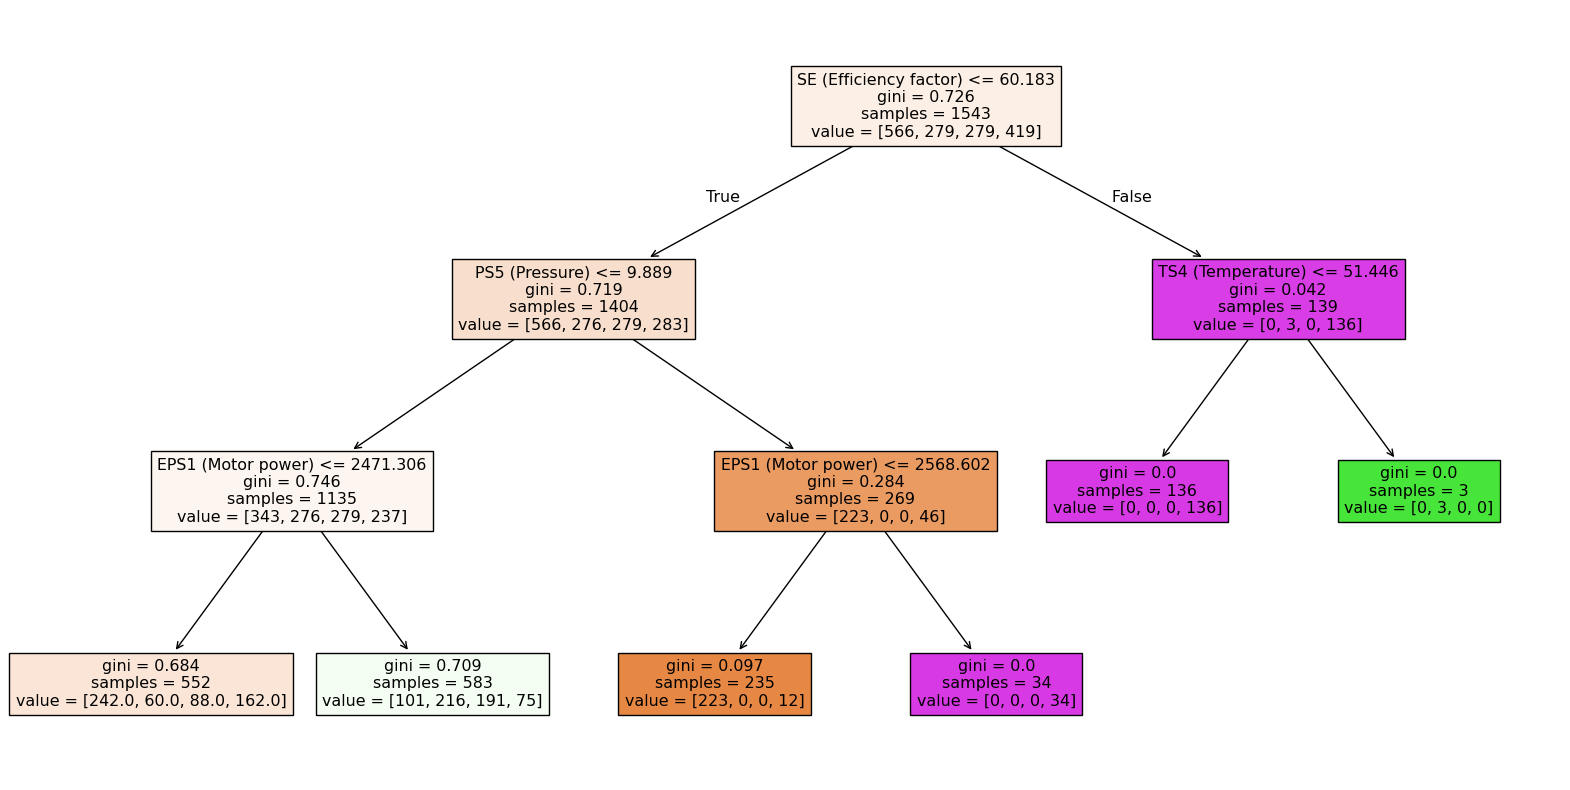

In [25]:
print(data.X.shape)
print(data.Attributes)
print(np.unique(data.Y_cooler, return_counts=True))

from sklearn import tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

targets = {
    "cooler":  data.Y_cooler,
    "valve":   data.Y_valve,
    "leakage": data.Y_leakage,
    "accu":    data.Y_accu,
}

models = {}
for name, Y in targets.items():
    X_train, X_test, Y_train, Y_test = train_test_split(
        data.X, Y, test_size=0.3, random_state=0, stratify=Y
    )
    clf = tree.DecisionTreeClassifier(random_state=0).fit(X_train, Y_train)
    models[name] = clf

    print(f"{name:8s} train={accuracy_score(Y_train, clf.predict(X_train)):.3f}  "
          f"test={accuracy_score(Y_test, clf.predict(X_test)):.3f}")

for name, clf in models.items():
    imp = clf.feature_importances_
    top = np.argsort(imp)[::-1][:3]
    print(name, [(data.Attributes[i], round(imp[i], 2)) for i in top])

clf = tree.DecisionTreeClassifier(max_depth=3, random_state=0).fit(X_train, Y_train)
plt.figure(figsize=(20, 10))
tree.plot_tree(clf, feature_names=data.Attributes, filled=True)
plt.show()